In [1]:

# ============================================================
# PHASE 4: EXPLORATORY DATA ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

from pathlib import Path

# Project configuration
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "Dataset"
    / "processed"
    / "GUIDE_Test_cleaned_v2.csv"
)

REPORT_PATH = (
    PROJECT_ROOT
    / "Dataset"
    / "processed"
    / "cleaning_report_v2.json"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "reports"
    / "figures"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Verify files
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"
assert REPORT_PATH.exists(), f"Cleaning report not found: {REPORT_PATH}"

print("Phase 4 environment initialized.")
print("Dataset:", DATA_PATH)
print("Figures directory:", FIGURE_DIR)


Phase 4 environment initialized.
Dataset: d:\Microsoft-SOC-Project\Dataset\processed\GUIDE_Test_cleaned_v2.csv
Figures directory: d:\Microsoft-SOC-Project\reports\figures


In [2]:

# ============================================================
# STEP 4.1: DATASET INSPECTION
# ============================================================

# Load a sample of 10,000 records
df_sample = pd.read_csv(
    DATA_PATH,
    nrows=10_000,
    low_memory=False
)

# Dataset overview
print("SAMPLE DATASET OVERVIEW")
print("-" * 50)

print("Sample rows:", len(df_sample))
print("Total columns:", len(df_sample.columns))

print("\nCOLUMN NAMES:")
print(df_sample.columns.tolist())

print("\nDATA TYPES:")
print(df_sample.dtypes)

print("\nFIRST 5 RECORDS:")
display(df_sample.head())

print("\nDATASET INFORMATION:")
df_sample.info()


SAMPLE DATASET OVERVIEW
--------------------------------------------------
Sample rows: 10000
Total columns: 46

COLUMN NAMES:
['Id', 'OrgId', 'IncidentId', 'AlertId', 'Timestamp', 'DetectorId', 'AlertTitle', 'Category', 'MitreTechniques', 'IncidentGrade', 'ActionGrouped', 'ActionGranular', 'EntityType', 'EvidenceRole', 'DeviceId', 'Sha256', 'IpAddress', 'Url', 'AccountSid', 'AccountUpn', 'AccountObjectId', 'AccountName', 'DeviceName', 'NetworkMessageId', 'EmailClusterId', 'RegistryKey', 'RegistryValueName', 'RegistryValueData', 'ApplicationId', 'ApplicationName', 'OAuthApplicationId', 'ThreatFamily', 'FileName', 'FolderPath', 'ResourceIdName', 'ResourceType', 'Roles', 'OSFamily', 'OSVersion', 'AntispamDirection', 'SuspicionLevel', 'LastVerdict', 'CountryCode', 'State', 'City', 'Usage']

DATA TYPES:
Id                      int64
OrgId                   int64
IncidentId              int64
AlertId                 int64
Timestamp                 str
DetectorId              int64
AlertTitl

,Id,OrgId,IncidentId,AlertId,Timestamp,DetectorId,AlertTitle,Category,MitreTechniques,IncidentGrade,...,Roles,OSFamily,OSVersion,AntispamDirection,SuspicionLevel,LastVerdict,CountryCode,State,City,Usage
0,1245540519230,657,11767,87199,2024-06-04T22:56:27Z,524,563,LateralMovement,T1021;T1047;T1105;T1569.002,BenignPositive,...,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630,Private
1,1400159342154,3,91158,632273,2024-06-03T12:58:26Z,2,2,CommandAndControl,NaN,BenignPositive,...,NaN,0,0,NaN,Suspicious,Suspicious,242,1445,10630,Public
2,1279900255923,145,32247,131719,2024-06-08T03:20:49Z,2932,10807,LateralMovement,T1021;T1027.002;T1027.005;T1105,BenignPositive,...,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630,Public
3,60129547292,222,15294,917686,2024-06-12T12:07:31Z,0,0,InitialAccess,T1078;T1078.004,FalsePositive,...,NaN,5,66,NaN,NaN,NaN,242,1445,10630,Public
4,515396080539,363,7615,5944,2024-06-06T17:42:05Z,27,18,Discovery,T1087;T1087.002,BenignPositive,...,Suspicious,5,66,NaN,NaN,NaN,242,1445,10630,Public



DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 46 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Id                  10000 non-null  int64  
 1   OrgId               10000 non-null  int64  
 2   IncidentId          10000 non-null  int64  
 3   AlertId             10000 non-null  int64  
 4   Timestamp           10000 non-null  str    
 5   DetectorId          10000 non-null  int64  
 6   AlertTitle          10000 non-null  int64  
 7   Category            10000 non-null  str    
 8   MitreTechniques     4465 non-null   str    
 9   IncidentGrade       10000 non-null  str    
 10  ActionGrouped       4 non-null      str    
 11  ActionGranular      4 non-null      str    
 12  EntityType          10000 non-null  str    
 13  EvidenceRole        10000 non-null  str    
 14  DeviceId            10000 non-null  int64  
 15  Sha256              10000 non-null  int64  

INCIDENT GRADE DISTRIBUTION


,Records,Percentage
BenignPositive,1752940,42.26
TruePositive,1492354,35.98
FalsePositive,902698,21.76


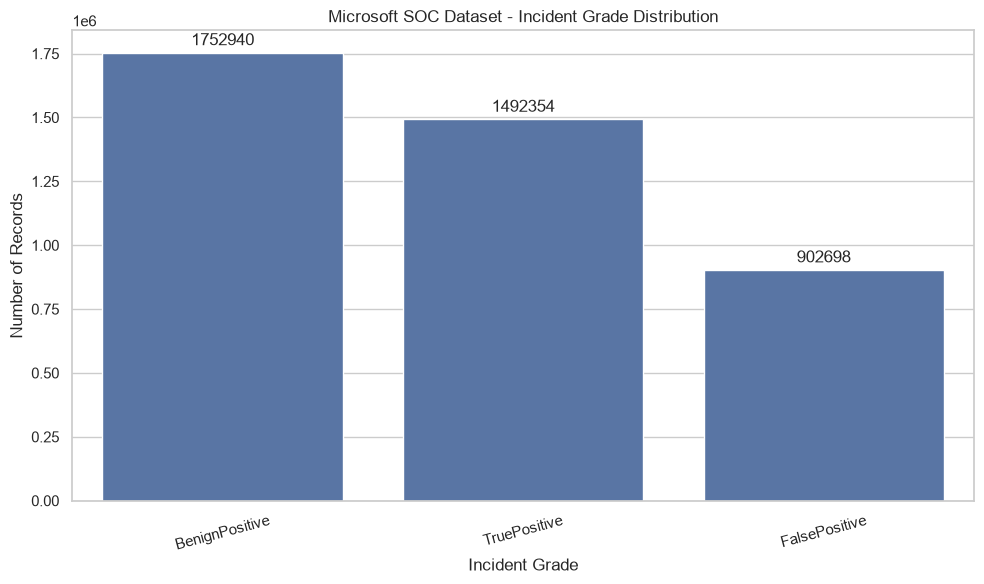

In [3]:

# ============================================================
# STEP 4.2: INCIDENT GRADE ANALYSIS
# ============================================================

# Load verified counts from the cleaning audit report
with open(REPORT_PATH, "r", encoding="utf-8") as file:
    cleaning_report = json.load(file)

incident_counts = pd.Series(
    cleaning_report["incident_grades"],
    name="Records"
)

# Calculate percentages
incident_percentages = (
    incident_counts / incident_counts.sum()
) * 100

incident_analysis = pd.DataFrame({
    "Records": incident_counts,
    "Percentage": incident_percentages.round(2)
})

incident_analysis = incident_analysis.sort_values(
    "Records",
    ascending=False
)

print("INCIDENT GRADE DISTRIBUTION")
display(incident_analysis)

# Bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=incident_analysis.index,
    y=incident_analysis["Records"]
)

plt.title("Microsoft SOC Dataset - Incident Grade Distribution")
plt.xlabel("Incident Grade")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)

# Add record counts above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "incident_grade_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


TOP 15 SECURITY ALERT CATEGORIES


,Records,Percentage
InitialAccess,1952969,47.08
Exfiltration,615284,14.83
SuspiciousActivity,440093,10.61
CommandAndControl,357179,8.61
Impact,307810,7.42
CredentialAccess,130196,3.14
Execution,115658,2.79
Malware,71593,1.73
Discovery,63633,1.53
Persistence,29075,0.70


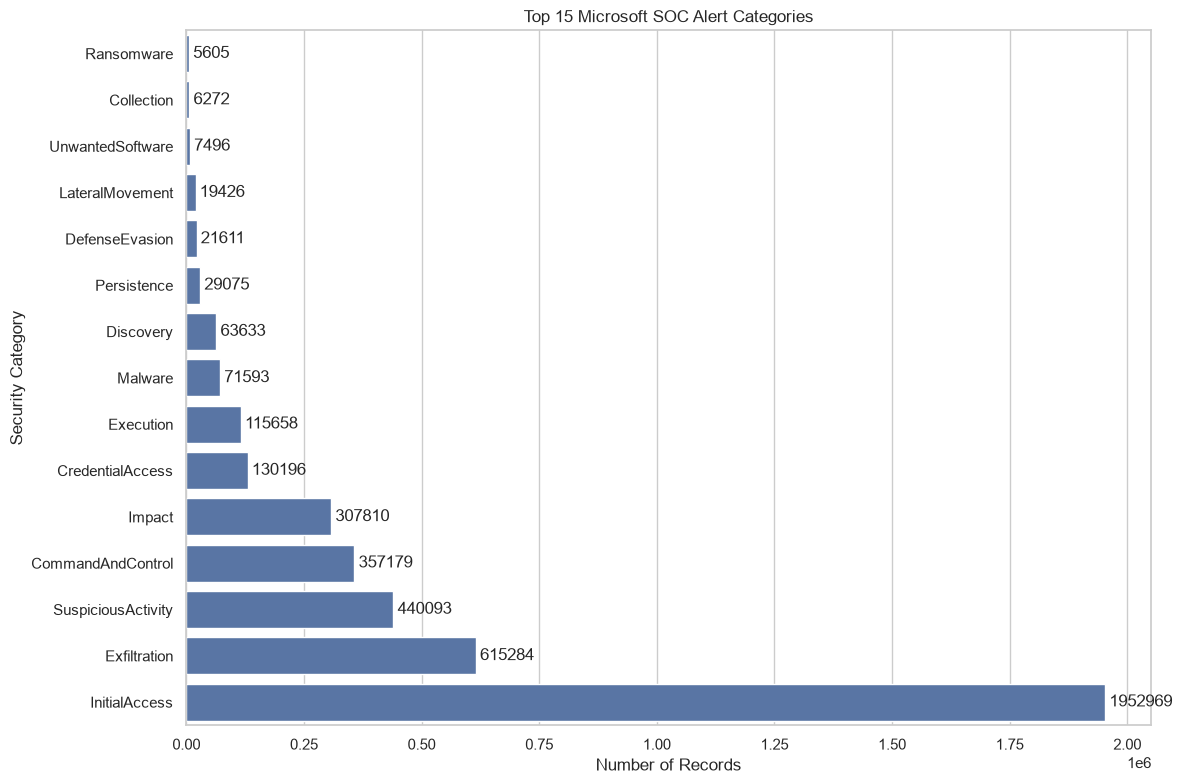

In [4]:

# ============================================================
# STEP 4.3: SECURITY CATEGORY ANALYSIS
# ============================================================

category_counts = pd.Series(
    cleaning_report["categories"],
    name="Records"
)

category_analysis = pd.DataFrame({
    "Records": category_counts
})

category_analysis = category_analysis.sort_values(
    "Records",
    ascending=False
)

category_analysis["Percentage"] = (
    category_analysis["Records"]
    / category_analysis["Records"].sum()
    * 100
).round(2)

print("TOP 15 SECURITY ALERT CATEGORIES")
display(category_analysis.head(15))

# Visualize top 15 categories
top_categories = category_analysis.head(15).sort_values(
    "Records",
    ascending=True
)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    x=top_categories["Records"],
    y=top_categories.index
)

plt.title("Top 15 Microsoft SOC Alert Categories")
plt.xlabel("Number of Records")
plt.ylabel("Security Category")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "top_security_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


TIME-BASED ALERT ANALYSIS
--------------------------------------------------
Total days: 152
Average daily alerts: 27289
Maximum daily alerts: 398093
Minimum daily alerts: 1

Top 10 days by alert volume:


,AlertCount
Date,
2024-06-04 00:00:00+00:00,398093
2024-06-03 00:00:00+00:00,391810
2024-06-06 00:00:00+00:00,381800
2024-06-05 00:00:00+00:00,334913
2024-06-13 00:00:00+00:00,300012
2024-06-07 00:00:00+00:00,299801
2024-06-11 00:00:00+00:00,297850
2024-06-10 00:00:00+00:00,278150
2024-06-12 00:00:00+00:00,271428


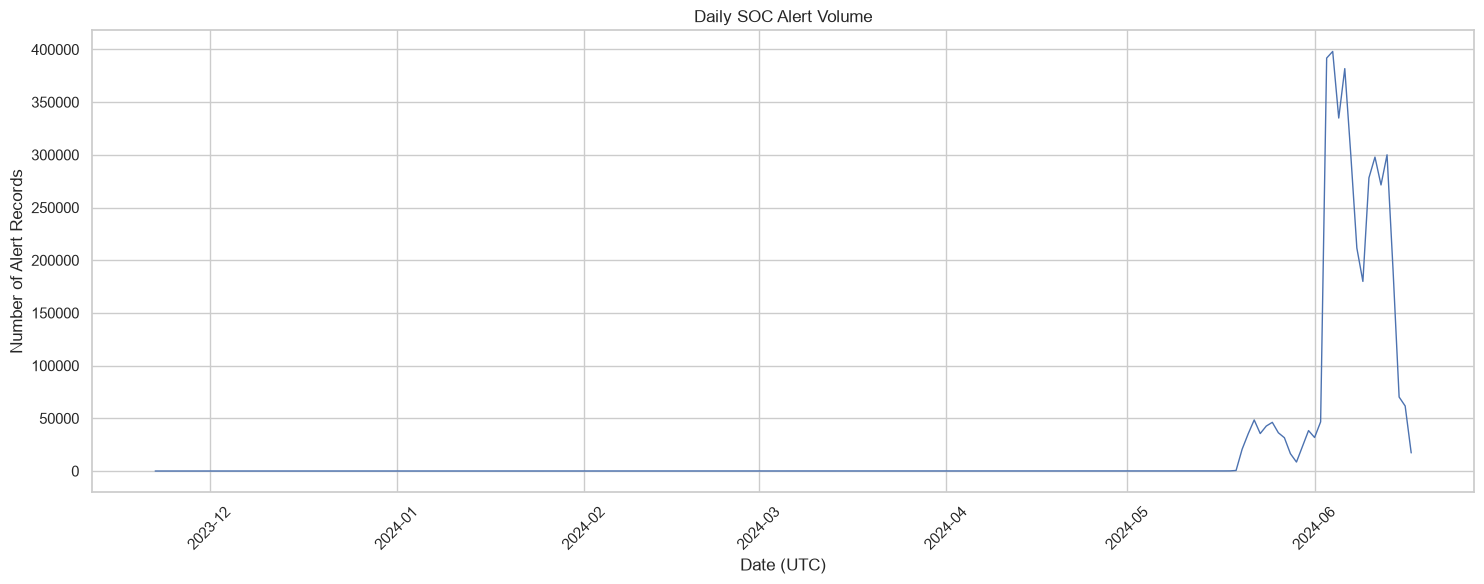

In [5]:

# ============================================================
# STEP 4.4: TIME-BASED ALERT ANALYSIS
# ============================================================

daily_alerts = {}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["Timestamp"],
    chunksize=100_000,
    dtype={"Timestamp": "string"},
    low_memory=False
):

    # Convert timestamps to UTC
    timestamps = pd.to_datetime(
        chunk["Timestamp"],
        errors="coerce",
        utc=True
    )

    # Count records per day
    daily_counts = timestamps.dt.floor("D").value_counts()

    for date, count in daily_counts.items():
        if pd.notna(date):
            daily_alerts[date] = (
                daily_alerts.get(date, 0) + int(count)
            )

# Create time-series DataFrame
daily_analysis = pd.DataFrame(
    list(daily_alerts.items()),
    columns=["Date", "AlertCount"]
)

daily_analysis = daily_analysis.sort_values("Date")
daily_analysis = daily_analysis.set_index("Date")

# Display summary
print("TIME-BASED ALERT ANALYSIS")
print("-" * 50)

print("Total days:", len(daily_analysis))
print("Average daily alerts:", round(daily_analysis["AlertCount"].mean()))
print("Maximum daily alerts:", daily_analysis["AlertCount"].max())
print("Minimum daily alerts:", daily_analysis["AlertCount"].min())

print("\nTop 10 days by alert volume:")
display(
    daily_analysis.sort_values(
        "AlertCount",
        ascending=False
    ).head(10)
)

# Plot daily alert volume
plt.figure(figsize=(15, 6))

plt.plot(
    daily_analysis.index,
    daily_analysis["AlertCount"],
    linewidth=1
)

plt.title("Daily SOC Alert Volume")
plt.xlabel("Date (UTC)")
plt.ylabel("Number of Alert Records")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "daily_alert_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


INCIDENT GRADE DISTRIBUTION ON PEAK DAYS


IncidentGrade,BenignPositive,FalsePositive,TruePositive
Date,,,
2024-06-03,165663,68990,157157
2024-06-04,150778,74528,172787
2024-06-05,149626,63632,121655
2024-06-06,151189,74807,155804



TOP 5 CATEGORIES ON EACH PEAK DAY

2024-06-03


,Date,Category,Records
9,2024-06-03,InitialAccess,204792
6,2024-06-03,Exfiltration,44002
15,2024-06-03,SuspiciousActivity,38796
1,2024-06-03,CommandAndControl,35414
11,2024-06-03,Malware,18521



2024-06-04


,Date,Category,Records
26,2024-06-04,InitialAccess,206095
23,2024-06-04,Exfiltration,67091
32,2024-06-04,SuspiciousActivity,43850
18,2024-06-04,CommandAndControl,37153
19,2024-06-04,CredentialAccess,11993



2024-06-05


,Date,Category,Records
43,2024-06-05,InitialAccess,147782
40,2024-06-05,Exfiltration,73949
49,2024-06-05,SuspiciousActivity,40395
35,2024-06-05,CommandAndControl,28837
36,2024-06-05,CredentialAccess,12199



2024-06-06


,Date,Category,Records
60,2024-06-06,InitialAccess,185182
57,2024-06-06,Exfiltration,81372
66,2024-06-06,SuspiciousActivity,41977
52,2024-06-06,CommandAndControl,31861
53,2024-06-06,CredentialAccess,12237


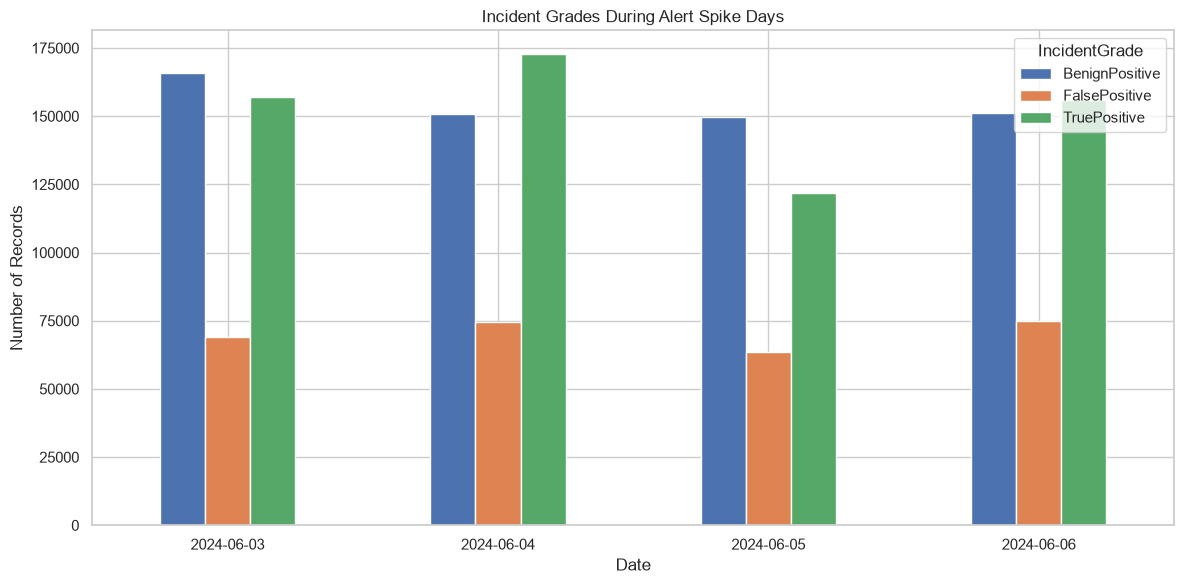

In [6]:

# ============================================================
# STEP 4.5: INVESTIGATE HIGH-VOLUME DAYS
# ============================================================

peak_days = {
    "2024-06-03",
    "2024-06-04",
    "2024-06-05",
    "2024-06-06"
}

grade_counts = {}
category_counts = {}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["Timestamp", "IncidentGrade", "Category"],
    chunksize=100_000,
    dtype="string",
    low_memory=False
):

    timestamps = pd.to_datetime(
        chunk["Timestamp"],
        errors="coerce",
        utc=True
    )

    chunk["Date"] = timestamps.dt.strftime("%Y-%m-%d")

    # Keep only records from the four peak days
    peak_data = chunk[chunk["Date"].isin(peak_days)]

    if peak_data.empty:
        continue

    # Count incident grades by date
    grade_group = peak_data.groupby(
        ["Date", "IncidentGrade"],
        dropna=False
    ).size()

    for key, count in grade_group.items():
        grade_counts[key] = grade_counts.get(key, 0) + int(count)

    # Count security categories by date
    category_group = peak_data.groupby(
        ["Date", "Category"],
        dropna=False
    ).size()

    for key, count in category_group.items():
        category_counts[key] = category_counts.get(key, 0) + int(count)


# Convert results into DataFrames
grade_df = (
    pd.Series(grade_counts, name="Records")
    .rename_axis(["Date", "IncidentGrade"])
    .reset_index()
)

category_df = (
    pd.Series(category_counts, name="Records")
    .rename_axis(["Date", "Category"])
    .reset_index()
)

print("INCIDENT GRADE DISTRIBUTION ON PEAK DAYS")
display(
    grade_df.pivot(
        index="Date",
        columns="IncidentGrade",
        values="Records"
    ).fillna(0).astype(int)
)

print("\nTOP 5 CATEGORIES ON EACH PEAK DAY")

for date in sorted(peak_days):

    print(f"\n{date}")

    display(
        category_df[category_df["Date"] == date]
        .sort_values("Records", ascending=False)
        .head(5)
    )


# Visualize incident grades
grade_pivot = grade_df.pivot(
    index="Date",
    columns="IncidentGrade",
    values="Records"
).fillna(0)

grade_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Incident Grades During Alert Spike Days")
plt.xlabel("Date")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "peak_days_incident_grades.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [7]:
# STEP 4.6.1: INSPECT MITRE TECHNIQUE VALUES

mitre_sample = pd.read_csv(
    DATA_PATH,
    usecols=["MitreTechniques"],
    nrows=20000,
    dtype="string"
)

print("Non-null values:")
print(mitre_sample["MitreTechniques"].notna().sum())

print("\nFirst 20 non-null examples:")
display(
    mitre_sample["MitreTechniques"]
    .dropna()
    .head(20)
)

print("\nMost common raw values:")
display(
    mitre_sample["MitreTechniques"]
    .value_counts()
    .head(15)
)

Non-null values:
8919

First 20 non-null examples:


0                       T1021;T1047;T1105;T1569.002
2                   T1021;T1027.002;T1027.005;T1105
3                                   T1078;T1078.004
4                                   T1087;T1087.002
5                                   T1078;T1078.004
11                                      T1111;T1557
13                                            T1566
21    T1007;T1016;T1018;T1049;T1087;T1135;T1574.007
31                                      T1568;T1008
38                      T1046;T1030;T1071;T1071.001
42                                        T1566.002
43                                  T1078;T1078.004
44                                  T1078;T1078.004
45                                  T1078;T1078.004
46                                        T1566.002
49                                        T1566.002
50                                            T1566
51                                  T1078;T1078.004
53                                  T1078;T1078.004
54          


Most common raw values:


MitreTechniques
T1078;T1078.004                              2956
T1566.002                                    1750
T1566                                        1272
T1133                                         549
T1566.001                                     332
T1110;T1110.003;T1110.001                     224
T1087;T1087.002                               164
T1559;T1106;T1059.005                          95
T1110                                          86
T1046;T1030;T1071;T1071.001                    70
T1078;T1098                                    70
T1027;T1027.002;T1027.005;T1105;T1204.002      70
T1046;T1071;T1210                              63
T1078                                          63
T1027;T1204.002                                63
Name: count, dtype: Int64

In [8]:
# STEP 4.6.2: COUNT INDIVIDUAL MITRE TECHNIQUES

from collections import Counter

technique_counts = Counter()
records_with_techniques = 0
total_records = 0

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["MitreTechniques"],
    chunksize=100_000,
    dtype="string"
):
    total_records += len(chunk)

    valid = chunk["MitreTechniques"].dropna()
    records_with_techniques += len(valid)

    for value in valid:
        techniques = [
            technique.strip()
            for technique in value.split(";")
            if technique.strip()
        ]
        technique_counts.update(set(techniques))

technique_df = pd.DataFrame(
    technique_counts.most_common(),
    columns=["MITRE_Technique", "Record_Count"]
)

print("Total dataset records:", total_records)
print("Records with MITRE techniques:", records_with_techniques)
print("Unique MITRE technique IDs:", len(technique_counts))

print("\nTOP 20 MITRE TECHNIQUES")
display(technique_df.head(20))

Total dataset records: 4147992
Records with MITRE techniques: 1840888
Unique MITRE technique IDs: 400

TOP 20 MITRE TECHNIQUES


,MITRE_Technique,Record_Count
0,T1078,659606
1,T1078.004,617374
2,T1566.002,360219
3,T1566,277038
4,T1133,119289
5,T1110,91296
6,T1566.001,61600
7,T1110.003,56980
8,T1110.001,56374
9,T1087,47866


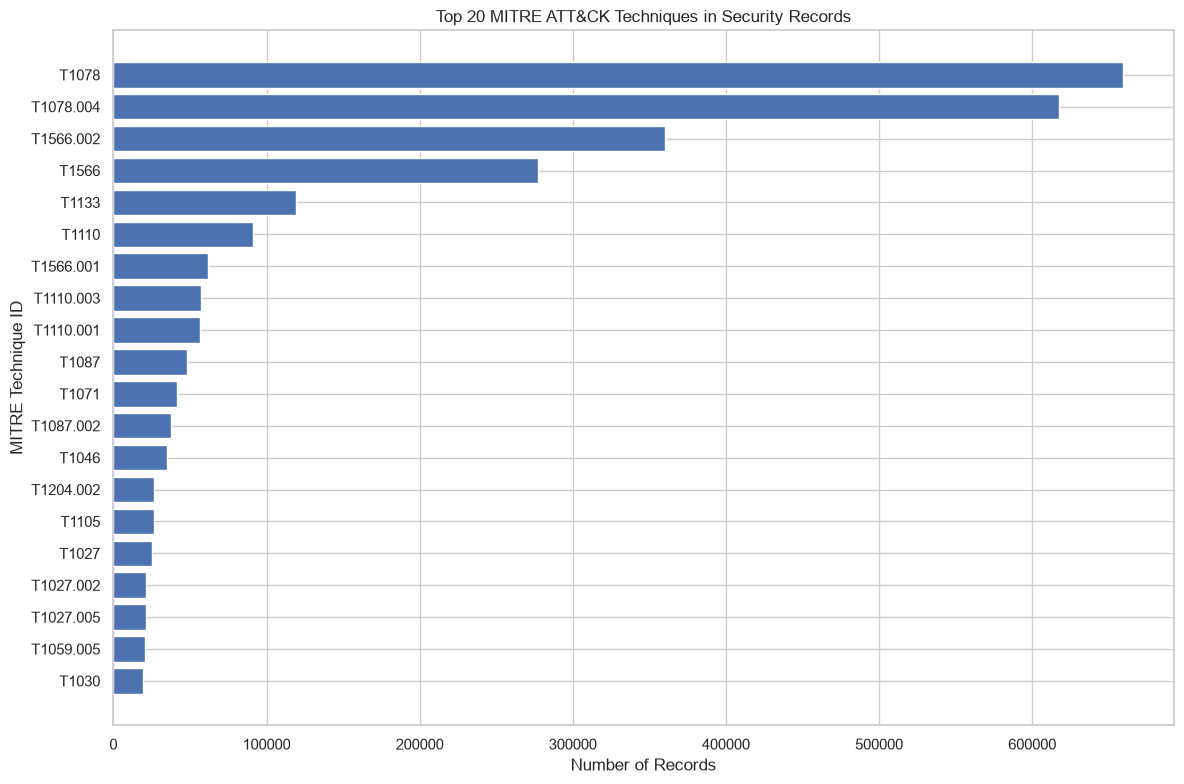

Chart saved: d:\Microsoft-SOC-Project\reports\figures\top_20_mitre_techniques.png


In [9]:
# STEP 4.6.3: VISUALIZE TOP 20 MITRE TECHNIQUES

top_20 = technique_df.head(20).sort_values(
    "Record_Count",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_20["MITRE_Technique"],
    top_20["Record_Count"]
)

plt.title("Top 20 MITRE ATT&CK Techniques in Security Records")
plt.xlabel("Number of Records")
plt.ylabel("MITRE Technique ID")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "top_20_mitre_techniques.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", FIGURE_DIR / "top_20_mitre_techniques.png")

In [11]:
# STEP 4.7.1: INSPECT ENTITY AND GEOGRAPHIC FIELDS

columns_to_inspect = [
    "EntityType",
    "EvidenceRole",
    "CountryCode",
    "State",
    "City",
    "DeviceId",
    "IpAddress",
    "AccountUpn"
]

entity_sample = pd.read_csv(
    DATA_PATH,
    usecols=columns_to_inspect,
    nrows=20000,
    dtype="string"
)

print("COLUMN SUMMARY")
display(
    pd.DataFrame({
        "Non_Null_Count": entity_sample.notna().sum(),
        "Unique_Values": entity_sample.nunique(dropna=True),
        "Missing_Percent": (
            entity_sample.isna().mean() * 100
        ).round(2)
    })
)

for column in columns_to_inspect:
    print(f"\nTOP 10 VALUES — {column}")
    display(
        entity_sample[column]
        .value_counts(dropna=False)
        .head(10)
    )

COLUMN SUMMARY


,Non_Null_Count,Unique_Values,Missing_Percent
EntityType,20000,21,0.0
EvidenceRole,20000,2,0.0
DeviceId,20000,653,0.0
IpAddress,20000,3403,0.0
AccountUpn,20000,6298,0.0
CountryCode,20000,80,0.0
State,20000,205,0.0
City,20000,327,0.0



TOP 10 VALUES — EntityType


EntityType
Ip                   4395
User                 4003
MailMessage          2323
Machine              1706
CloudLogonRequest    1456
Url                  1436
File                 1401
Mailbox               977
Process               821
CloudApplication      470
Name: count, dtype: Int64


TOP 10 VALUES — EvidenceRole


EvidenceRole
Related     11020
Impacted     8980
Name: count, dtype: Int64

... (8 outputs left out)


TOP 10 VALUES — IpAddress


IpAddress
360606    15609
0            23
3            21
8            19
2            19
5            18
6            18
10           17
1            15
12           14
Name: count, dtype: Int64


TOP 10 VALUES — AccountUpn


AccountUpn
673934    12954
0            33
8            18
11           16
1            15
16           15
3            15
2            14
4            13
10           13
Name: count, dtype: Int64

In [12]:
# STEP 4.7.2: FULL-DATASET ENTITY AND GEOGRAPHIC ANALYSIS

from collections import Counter

entity_counts = Counter()
evidence_counts = Counter()
country_counts = Counter()
state_counts = Counter()
city_counts = Counter()

total_records = 0

columns = [
    "EntityType",
    "EvidenceRole",
    "CountryCode",
    "State",
    "City"
]

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    chunksize=100_000,
    dtype="string"
):
    total_records += len(chunk)

    for column, counter in [
        ("EntityType", entity_counts),
        ("EvidenceRole", evidence_counts),
        ("CountryCode", country_counts),
        ("State", state_counts),
        ("City", city_counts)
    ]:
        counter.update(chunk[column].dropna().tolist())

print("Total records processed:", total_records)

print("\nTOP 15 ENTITY TYPES")
display(pd.DataFrame(
    entity_counts.most_common(15),
    columns=["EntityType", "Record_Count"]
))

print("\nEVIDENCE ROLE DISTRIBUTION")
display(pd.DataFrame(
    evidence_counts.most_common(),
    columns=["EvidenceRole", "Record_Count"]
))

print("\nTOP 15 COUNTRY CODE VALUES")
display(pd.DataFrame(
    country_counts.most_common(15),
    columns=["CountryCode_ID", "Record_Count"]
))

print("\nTOP 15 STATE CODE VALUES")
display(pd.DataFrame(
    state_counts.most_common(15),
    columns=["State_ID", "Record_Count"]
))

print("\nTOP 15 CITY CODE VALUES")
display(pd.DataFrame(
    city_counts.most_common(15),
    columns=["City_ID", "Record_Count"]
))

Total records processed: 4147992

TOP 15 ENTITY TYPES


,EntityType,Record_Count
0,Ip,929684
1,User,831162
2,MailMessage,479227
3,Machine,348147
4,CloudLogonRequest,298656
5,Url,294913
6,File,290887
7,Mailbox,205624
8,Process,165178
9,MailCluster,96901



EVIDENCE ROLE DISTRIBUTION


,EvidenceRole,Record_Count
0,Related,2288528
1,Impacted,1859464



TOP 15 COUNTRY CODE VALUES


,CountryCode_ID,Record_Count
0,242,3795038
1,0,81396
2,1,46221
3,2,27576
4,3,20476
5,4,16620
6,5,12999
7,7,10022
8,11,9108
9,8,8752



TOP 15 STATE CODE VALUES


,State_ID,Record_Count
0,1445,3851530
1,0,44834
2,1,19759
3,2,15505
4,3,10493
5,5,8493
6,4,7570
7,8,7199
8,7,6848
9,6,6835



TOP 15 CITY CODE VALUES


,City_ID,Record_Count
0,10630,3851080
1,0,44651
2,1,11673
3,2,10456
4,3,7106
5,6,6997
6,4,6836
7,7,6014
8,5,5943
9,8,4895


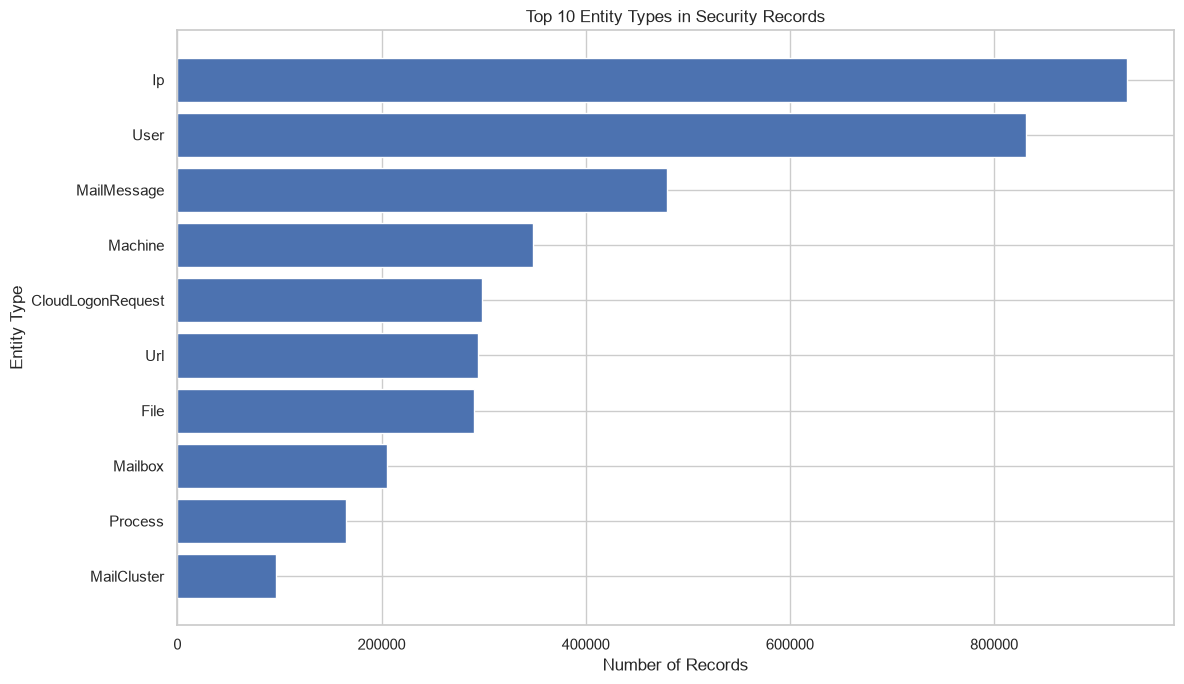

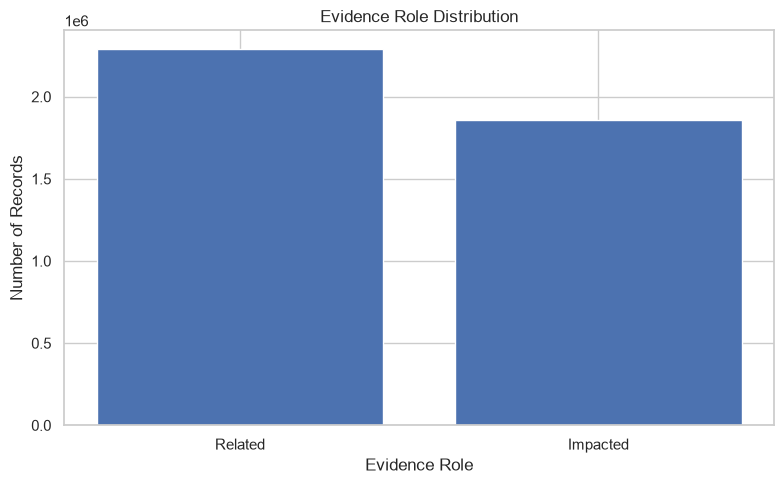

Both charts saved successfully.


In [13]:
# STEP 4.7.3: ENTITY AND EVIDENCE VISUALIZATIONS

# Chart 1: Top 10 entity types
entity_df = pd.DataFrame(
    entity_counts.most_common(10),
    columns=["EntityType", "Record_Count"]
).sort_values("Record_Count", ascending=True)

plt.figure(figsize=(12, 7))
plt.barh(entity_df["EntityType"], entity_df["Record_Count"])
plt.title("Top 10 Entity Types in Security Records")
plt.xlabel("Number of Records")
plt.ylabel("Entity Type")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "top_10_entity_types.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Chart 2: Evidence role distribution
evidence_df = pd.DataFrame(
    evidence_counts.most_common(),
    columns=["EvidenceRole", "Record_Count"]
)

plt.figure(figsize=(8, 5))
plt.bar(evidence_df["EvidenceRole"], evidence_df["Record_Count"])
plt.title("Evidence Role Distribution")
plt.xlabel("Evidence Role")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "evidence_role_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Both charts saved successfully.")